In [27]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from xgboost import XGBRegressor
from xgboost import plot_importance as xgd_plot_importance
from lightgbm import LGBMRegressor
from lightgbm import plot_importance as lgbm_plot_importance
from sklearn.metrics import r2_score

In [2]:
test_data = pd.read_csv('/Users/phillipphi/Desktop/IDX Exchange/test_data.csv')
training_data = pd.read_csv('/Users/phillipphi/Desktop/IDX Exchange/training_data.csv')

training_x = training_data.drop('ClosePrice', axis=1)
training_y = training_data.ClosePrice

test_x = test_data.drop('ClosePrice', axis=1)
test_y = test_data.ClosePrice

In [ ]:
# creates our XGBoost model

xgd = XGBRegressor()

xgd.fit(training_x, training_y)
xgd_test_pred = xgd.predict(test_x)

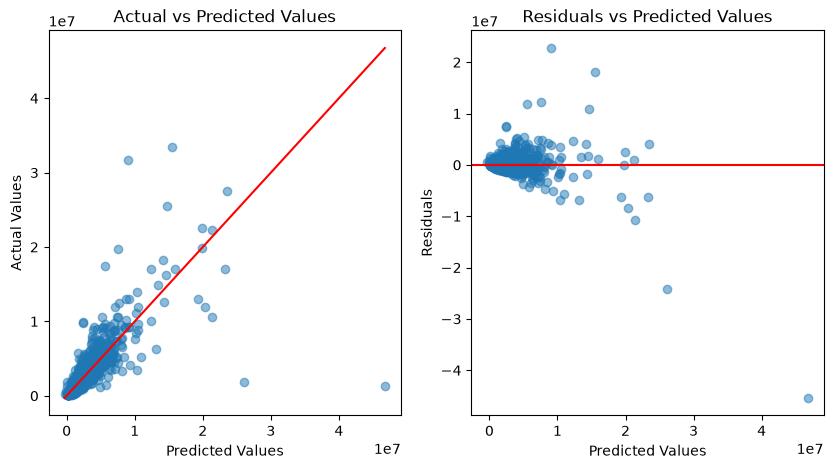

In [10]:
# creates plots for the XGBoost model

plt.figure(figsize=(10, 5))

# plots the actual vs predicted values for the test data
plt.subplot(1, 2, 1)
plt.scatter(xgd_test_pred, test_y, alpha=0.5)
plt.plot([min(xgd_test_pred), max(xgd_test_pred)], [min(xgd_test_pred), max(xgd_test_pred)], color='red')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.title('Actual vs Predicted Values')

# plots the residuals vs predicted values for the test data
plt.subplot(1, 2, 2)
residuals = test_y - xgd_test_pred
plt.scatter(xgd_test_pred, residuals, alpha=0.5)
plt.axhline(0, color='red')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted Values')

plt.show()


<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

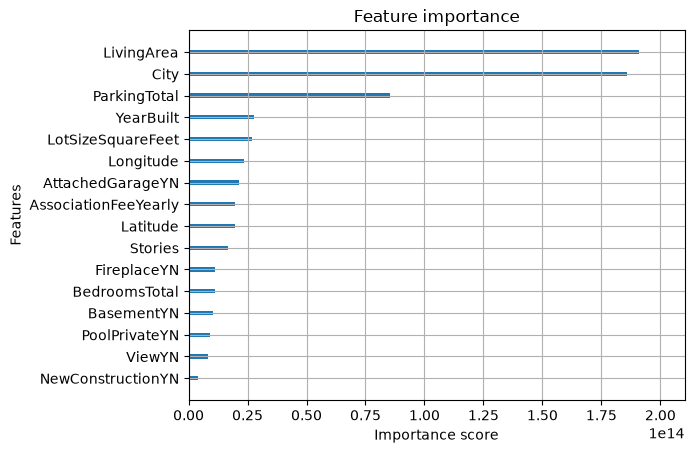

In [25]:
# creates barplots of the importance values of each attribute 
# LivingArea and City appear to be the most important variables
# this is consistent with the importance values of our random forest model

xgd_plot_importance(xgd, importance_type='gain', show_values=False)

In [17]:
# calculates our testing R^2 and mdape values

xgd_r2 = r2_score(test_y, xgd_test_pred)
print(f"XGBoost R^2: {xgd_r2}")

xgd_mdape = np.median(np.abs((test_y - xgd_test_pred) / test_y)) * 100
print(f"XGBoost Median Absolute Percentage Error: {xgd_mdape}")

XGBoost R^2: 0.6876017496938018
XGBoost Median Absolute Percentage Error: 9.945363372093023


In [19]:
# creates our LightGBM model

lightgbm = LGBMRegressor()
lightgbm.fit(training_x, training_y)

lightgbm_test_pred = lightgbm.predict(test_x)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004750 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1694
[LightGBM] [Info] Number of data points in the train set: 111190, number of used features: 16
[LightGBM] [Info] Start training from score 1243334.248156


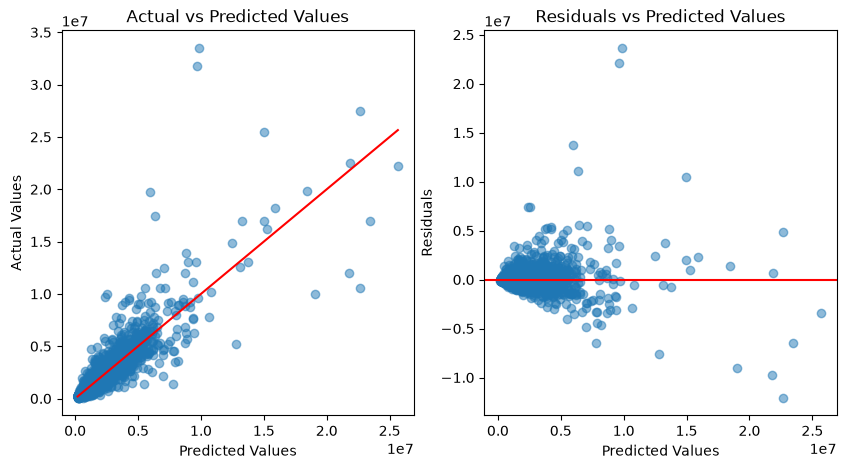

In [20]:
# creates plots for the LightGBM model

plt.figure(figsize=(10, 5))

# plots the actual vs predicted values for the test data
plt.subplot(1, 2, 1)
plt.scatter(lightgbm_test_pred, test_y, alpha=0.5)
plt.plot([min(lightgbm_test_pred), max(lightgbm_test_pred)], [min(lightgbm_test_pred), max(lightgbm_test_pred)], color='red')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.title('Actual vs Predicted Values')

# plots the residuals vs predicted values for the test data
plt.subplot(1, 2, 2)
residuals = test_y - lightgbm_test_pred
plt.scatter(lightgbm_test_pred, residuals, alpha=0.5)
plt.axhline(0, color='red')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted Values')

plt.show()


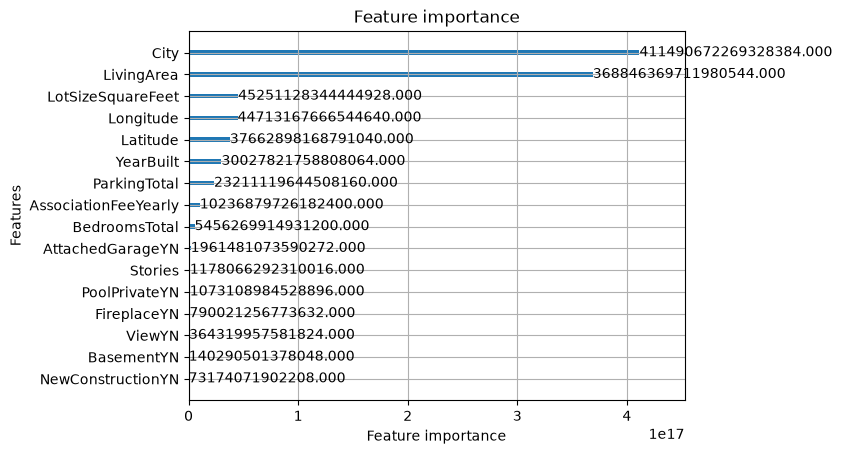

In [ ]:
# creates barplots of the importance values of each attribute for our LightGBM model

lgbm_plot_importance(lightgbm, importance_type='gain')
plt.show()

In [40]:
# calculates our testing R^2 and mdape values for LightGBM

lightgbm_r2 = r2_score(test_y, lightgbm_test_pred)
print(f"LightGBM R^2: {lightgbm_r2}")

lightgbm_mdape = np.median(np.abs((test_y - lightgbm_test_pred) / test_y)) * 100
print(f"LightGBM Median Absolute Percentage Error: {lightgbm_mdape}")

LightGBM R^2: 0.7922787751032643
LightGBM Median Absolute Percentage Error: 11.341383576113957
